# U1 Problemas Relatividad
### Física Electrónica - UTN FRA
*Cuaderno interactivo adaptado para Google Colab.*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output
import time

# --- Configuración de la Interfaz ---
btn_play = widgets.Button(description="Iniciar Animación", button_style='primary', icon='play')
slider_v = widgets.FloatSlider(value=0.6, min=0.0, max=0.99, step=0.01, description='Velocidad (v):')
output_plot = widgets.Output()

def dibujar_escenario(t, v):
    c = 1.0    # Velocidad de la luz
    L = 6.0    # Longitud del tren (medida en S)

    with output_plot:
        clear_output(wait=True)
        fig, ax = plt.subplots(figsize=(16, 7))

        # Ajuste de límites y estética
        ax.set_xlim(-10, 15)
        ax.set_ylim(-2, 2.5)
        ax.set_aspect('equal')
        ax.axis('off')

        # 1. Sistema S: Andén (En reposo)
        ax.plot([-10, 15], [-0.8, -0.8], color='black', lw=3)
        ax.plot(0, -0.6, 'go', markersize=15, label='Observador en S')
        ax.text(0, -1.3, "SISTEMA S (Andén)", color='green', ha='center', fontsize=14, fontweight='bold')

        # Etiquetado de puntos de impacto A y B en S
        ax.plot(-L/2, -0.8, 'kx', markersize=10)
        ax.plot(L/2, -0.8, 'kx', markersize=10)
        ax.text(-L/2, -1.1, "Punto A", ha='center', fontsize=12)
        ax.text(L/2, -1.1, "Punto B", ha='center', fontsize=12)

        # 2. Sistema S': Tren (En movimiento)
        x_centro_tren = v * t
        rect_tren = plt.Rectangle((x_centro_tren - L/2, 0.2), L, 1.0,
                                  color='gray', alpha=0.2, ec='black', lw=3)

        ax.add_patch(rect_tren)
        ax.plot(x_centro_tren, 0.7, 'ro', markersize=15, label="Observador en S'")
        ax.text(x_centro_tren, 1.4, f"SISTEMA S' (v = {v}c)", color='red', ha='center', fontsize=14, fontweight='bold')

        # 3. Propagación de los destellos (Frentes de onda)
        radio = c * t
        # Frente A (azul) y Frente B (naranja)
        luz_A = plt.Circle((-L/2, 0.7), radio, color='blue', fill=False, lw=2, ls='--', alpha=0.6)
        luz_B = plt.Circle((L/2, 0.7), radio, color='darkorange', fill=False, lw=2, ls='--', alpha=0.6)
        ax.add_patch(luz_A)
        ax.add_patch(luz_B)

        # 4. Lógica de Detección en S' (Relatividad de la Simultaneidad)
        # Distancia desde los puntos de emisión hasta la posición actual del observador en S'
        dist_B_S_prime = abs(x_centro_tren - (L/2))
        dist_A_S_prime = abs(x_centro_tren - (-L/2))

        if radio >= dist_B_S_prime:
            ax.annotate("⚡ Destello B detectado en S'", xy=(x_centro_tren, 0.7), xytext=(x_centro_tren + 1.5, 2.0),
                        arrowprops=dict(arrowstyle="->", color='orange', lw=2),
                        color='darkorange', fontsize=14, fontweight='bold',
                        bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="orange", lw=2))

        if radio >= dist_A_S_prime:
            ax.annotate("⚡ Destello A detectado en S'", xy=(x_centro_tren, 0.7), xytext=(x_centro_tren - 5.5, 2.0),
                        arrowprops=dict(arrowstyle="->", color='blue', lw=2),
                        color='blue', fontsize=14, fontweight='bold',
                        bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="blue", lw=2))

        plt.title(f"Simultaneidad Relativista | t = {t:.2f} s", fontsize=20, pad=25)
        ax.legend(loc='upper right', fontsize=12)
        plt.show()

def iniciar_animacion(b):
    btn_play.disabled = True
    slider_v.disabled = True
    for t in np.arange(0, 8.1, 0.1):
        dibujar_escenario(t, slider_v.value)
        time.sleep(0.04)
    btn_play.disabled = False
    slider_v.disabled = False

btn_play.on_click(iniciar_animacion)

# Layout
display(widgets.VBox([widgets.HBox([btn_play, slider_v]), output_plot]))
dibujar_escenario(0, slider_v.value)

#Problema dilatación temporal
<img width="150" height="150"  src="https://res.cloudinary.com/drruqi1kg/image/upload/v1678280077/kisspng-rocket-spacecraft-cartoon-clip-art-cartoon-spaceship-pictures-5aaa3f240d8740.2873013315211067240554_ehdjlz.png"></img>

<h1 style="font-size: 24px;">
Un cohete viaja a una velocidad constante de 0.6c (es decir, el 60% de la velocidad de la luz) con respecto a un observador en la Tierra. En el cohete, hay un reloj que marca el tiempo propio del cohete (es decir, el tiempo medido por un observador en el cohete). Si el cohete viaja durante 10 años según el tiempo propio del cohete, ¿cuántos años han pasado según el reloj de un observador en la Tierra?</h1>



#Formulas


In [ ]:
from IPython.display import Latex
from IPython.display import HTML
html_string = '<div style="font-size: 20px;">Pista: Puedes usar la fórmula de dilatación del tiempo de la relatividad especial para resolver este problema. La fórmula para el factor de Lorentz es:</div>'
display(HTML(html_string))
# Definir una fórmula en LaTeX con fuente grande
gamma = r'$\large \gamma =\frac{1}{\sqrt{1 - \frac{v^2}{c^2}}}$'
display(Latex(gamma))
html_string = '<div style="font-size: 20px;">La fórmula para la dilatación del tiempo es:")</div>'
display(HTML(html_string))
# Mostrar la fórmula en la salida de la celda
tTierra = r'$\large t_{tierra} = \gamma \cdot t_{cohete}$'
display(Latex(tTierra))

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

# Resolución python


In [ ]:
import numpy as np
from IPython.display import Latex
# Velocidad del cohete en unidades de c
v = 0.6
# Tiempo propio del cohete en años
tp = 10
# Factor de Lorentz
gamma = 1 / np.sqrt(1 - v**2)
# Tiempo medido por el observador en la Tierra
tt = tp * gamma
print("Según el observador en la Tierra, han pasado", round(tt, 3), "años.")


Según el observador en la Tierra, han pasado 12.5 años.



# La Paradoja de los gemelos
## Datos
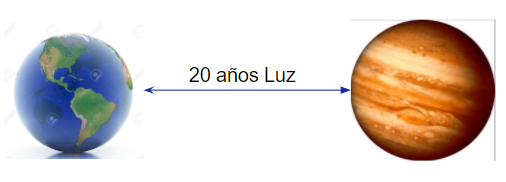




<h1 style="font-size: 24px;">

*  Hay dos gemelos cuando tienen 20 años uno de ellos viaja (lo llamaremos viajero)  al planeta X el otro se queda en la tierra y lo llamaremos gemelo terrestre.
*  El planeta X, que se encuentra a 20 años luz.
*  La nave viaja a 0.95 C (95% de la velocidad de la luz)
*  C  300 000 Km/s
</h1>

##Calcular:
1. Velocidad de la nave en km/s
2. Tiempo de viaje (t) gemelo terrestre
3. Gamma
4.  t’ (tiempo gemelo viajero)
5. Edad de los gemelos al concluir el viaje



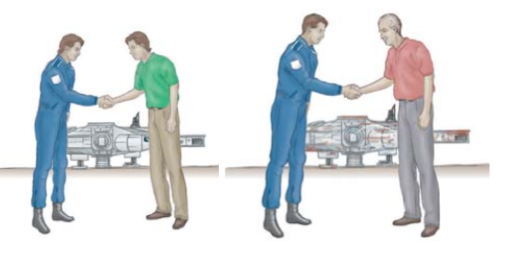

# Punto 1

In [ ]:
velocidadLuz = 300000 #km/s
velocidadNave=0.95 * velocidadLuz
print(str(velocidadNave) + " km/s")

285000.0 km/s


#Punto 2

In [ ]:
distanciaPlaneta = 20 #años luz
velocidadNaveC=0.95
tiempoDeViaje= (distanciaPlaneta/velocidadNaveC)*2
print ("t= " + str(tiempoDeViaje)+" años")

t= 42.10526315789474 años


#Punto 3


<font size="10"> $\gamma=\frac{1}{a}=\frac{1}{\sqrt{1-\frac{v^2}{c^2}}}$

In [ ]:
import math
C=1
v = velocidadNaveC
beta = v/C

a = math.sqrt(1-(beta**2))

gamma = 1/a

print(gamma)
print(a)


3.202563076101742
0.31224989991991997


#Punto 4

<font size="10"> $t'=\frac{t}{\gamma}$

In [ ]:
tPrima = tiempoDeViaje / gamma

print ("t'= " + str(tPrima) + " años")

t'= 13.147364207154526 años


#Punto 5


In [ ]:
edadInicial = 20
gemeloEnTierra = edadInicial + tiempoDeViaje

gemeloViajero = edadInicial + tPrima

print("Edad de gemelo en tierra :" + str(gemeloEnTierra)+" años" +"\n"+ "Edad gemelo Viajero :"+ str(gemeloViajero)+" años")

Edad de gemelo en tierra :62.10526315789474 años
Edad gemelo Viajero :33.147364207154524 años


#Velocidad relativa de dos naves
Dos naves espaciales A y B se mueven en direcciones opuestas como se muestra en la figura Un observador en la Tierra mide la rapidez de la nave espacial A en 0.750c y la rapidez de la nave espacial B en 0.850c. Encuentre la velocidad de la nave espacial B como la observa la tripulación de la nave espacial A.
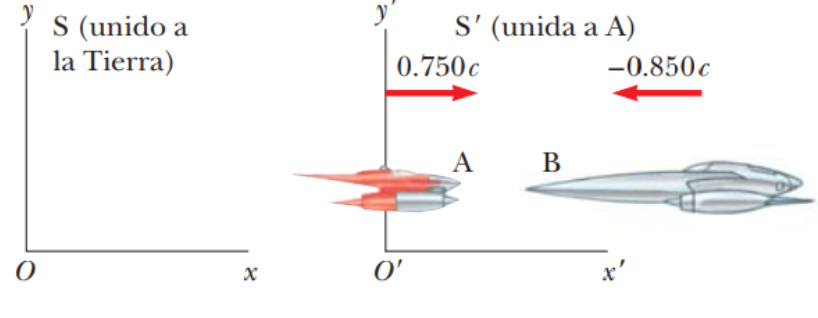

Existen dos observadores, uno en la Tierra (O) y uno (O')
en la nave espacial A. El evento es el movimiento de la nave espacial B.

#Solucion dos Naves


Porque el problema pide encontrar una velocidad observada, este ejemplo se clasifica como uno que requiere la transformación de velocidad de Lorentz.
El observador con base en la Tierra, en reposo en el marco S, hace dos mediciones, una de cada nave espacial. Se quiere encontrar la velocidad de la nave espacial B medida por la tripulación de la nave espacial A. Por lo tanto, ux =-0.850c. La velocidad de la nave espacial A también es la velocidad del observador en reposo en la nave espacial A (el marco S’) relativo al observador en reposo en la Tierra. Por tanto, v 0.750c.
\
$u_x=-0.850c$
\
$v=0.750c$
\

<font size="10">$u'_x=\frac{u_x-v}{1-\frac{u_x.v}{c^2}}$
</font>




In [ ]:
ux = -0.850
v = 0.750
#ux = -0.5
#v = 0.5
c=1
a= (ux) * (v)
print("a= (ux) * (v) =" + str(a))
b = ux - v
print("b = ux - v = "+ str(b))
d= a/c**2
print("d= a/c**2 = "+ str(d))

uPrimax= b / (1-d)
print("u'x = "   + str(uPrimax)+ " c")


a= (ux) * (v) =-0.6375
b = ux - v = -1.6
d= a/c**2 = -0.6375
u'x = -0.9770992366412214 c


# Problema   Cantidad de movimiento lineal de un electrón


Datos del problema:
masa=9.11  10-31 kg    rapidez de 0.4 C
C= 299.792.458 m/s.

Encuentre la magnitud de su cantidad de movimiento relativista y compare este valor con la cantidad de movimiento calculada a partir de la expresión clásica.
Resultados expresados en [kg.m / s]

#solución
Cantidad movimiento clasico\
<font size="10">$Pc=  m . v$ </font>

Cantidad movimiento relativista\

<font size="10">$Pr= \gamma . m . v$ </font>



In [3]:
masa= 9.11e-31  # kg
c = 299792458 #m/s

velocidadElectron= 0.4* c
cantidadMovimientoClasico = masa * velocidadElectron

print("cantidad de movimiento Clasico = "+ str(cantidadMovimientoClasico)+ " kg.m/s")

cantidad de movimiento Clasico = 1.092443716952e-22 kg.m/s


In [4]:
import math


v = velocidadElectron
beta = v/c

a = math.sqrt(1-(beta**2))

gamma = 1/a

print("coeficiente relativista Gamma= "+ str(gamma))

cantidadMovimientoRelativista = masa * v * gamma

print("cantidad de movimiento Relativista = "+ str(cantidadMovimientoRelativista)+ " kg.m/s")

coeficiente relativista Gamma= 1.0910894511799618
cantidad de movimiento Relativista = 1.1919538155741552e-22 kg.m/s


# Parte 2
la carga del electron es de
1,602 x 10-19 C

e.V =.5 m v^2\
V=.5 * m * gamma  v^2/e

In [5]:
e=1.602e-19
c = 299792458

masa= 9.11e-31  # kg
V= (0.5 * v**2 * masa) * gamma / e
print(V)

44611.581047872


#2.9 Problema Enerigía Relativista
Dos protones (cada uno con M = 1.67 x 10-27 kg) se desplazan inicialmente con la misma rapidez en sentidos opuestos, y siguen existiendo después de un choque frontal que produce además un pión neutro de masa m = 2.40 x 10-28 kg (figura) . Si los protones y el pión están en reposo después de la colisión, determine la rapidez inicial de los protones. La energía se conserva durante el choque.

<img src="https://res.cloudinary.com/drruqi1kg/image/upload/v1677692388/Screenshot_2_e4uuvs.jpg">.



#2.9 Resolución Problema Enerigía Relativista
<img src="https://res.cloudinary.com/drruqi1kg/image/upload/v1677692388/Screenshot_2_e4uuvs.jpg">

**Datos**

*   M masa del protón
*   m masa del Pión
*   La energía total relativista, la cual se conserva en el choque.

**Calcular**  
* La rapidez v




#paso 1
la energia de cada proton antes del choque es:

$E_{prot}=\gamma M.c{^2}$

Osea que la energia total antes del choque era:

:

$E_{TotalAntesDelChoque}=2.\gamma M.c{^2}$

la energía total luego del choque es:

$E_{TotalDespuesDelChoque} = 2(Mc^2) + mc^2$

Puedo despejar $\gamma$ obteniendo



#paso 2

Igualo las energías antes y despues del choque

$2.(\gamma M.c{^2})= 2(Mc^2) + mc^2$


#paso 3
Despejo $\gamma$



$\gamma= 1 + \frac{m}{2M}$

In [ ]:
masaPion = 2.40e-28
masaProton = 1.67e-27

gamma = 1+ (masaPion/(2*masaProton))
print("gamma vale: ", gamma)

gamma vale:  1.0718562874251496


#paso 4

recordando la formula de $gamma$

$\gamma = \frac{1}{\sqrt{1-\frac{v^2}{c^2}}}$

#paso 5 despejo v y calculo



$v= c \sqrt{1-(\frac{1}{\gamma})^2}$ =

In [ ]:
import math
segundoTermino = 1/gamma
sT2 = segundoTermino**2

raiz= math.sqrt (1-sT2)
c = 1
v = c * raiz
print("velocidad en fracciones de la velocidad de la luz : ", v,"c")
c= 299792.458
v = c * raiz
print("velocidad en km/s : ", v, "km/s")

velocidad en fracciones de la velocidad de la luz :  0.359977736169542 c
velocidad en km/s :  107918.61035154249 km/s
